In [84]:
# !pip install torch torchvision scikit-learn seaborn matplotlib
# !pip install dataset
# !pip install torchattacks

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━ 2/5 [chardet]  WARNING: The script chardetect is installed in '/mnt/ceph/maha1364/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [torchattacks] [torchattacks]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.0.1 requires requests>=2.32.2, but you have requests 2.25.1 which is incompatible.
conda 26.1.1 requires requests<3,>=2.28.0, but you have requests 2.25.1 which is incompatible.
conda-libmamba-solver 25.11.0 requires requests<3,>=2.28.0, but you have requests 2.25.1 which is incompatible.
jupyterlab-server 2.28.0 requires requests>=2.31, but you have requests 2.25.1 which is inco

In [7]:
# #!/bin/bash
# !curl -L -o ./brian_tumor_dataset.zip\
#   https://www.kaggle.com/api/v1/datasets/download/preetviradiya/brian-tumor-dataset

In [8]:
# !unzip brian_tumor_dataset

In [121]:
import importlib
import sys
import src
import numpy as np
import torch
import matplotlib.pyplot as plt

In [55]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        # Ensure deterministic behavior for cuDNN
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

In [168]:
def show_test_samples(test_loader, classes, num_samples_per_class=2):
    """
    Finds and displays exactly two sample images for each class from the test loader.
    """
    num_classes = len(classes)
    # Dictionary to keep track of collected images per class index
    samples_per_class = {i: [] for i in range(num_classes)}
    
    # Iterate through the test loader until we have 2 images for every class
    for batch in test_loader:
        images, labels = batch[0], batch[1]
        for img, label in zip(images, labels):
            lbl_idx = label.item()
            if len(samples_per_class[lbl_idx]) < num_samples_per_class:
                samples_per_class[lbl_idx].append(img)
        
        # Stop early once all classes have 2 samples
        if all(len(v) == 2 for v in samples_per_class.values()):
            break

    # Normalization parameters for unnormalizing pretrained inputs
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # Plotting grid (Rows = Classes, Columns = 2 samples)
    fig, axes = plt.subplots(num_classes, 2, figsize=(6, 3 * num_classes))
    
    # Handle edge case if there is only 1 class
    if num_classes == 1:
        axes = np.expand_dims(axes, axis=0)

    for cls_idx, class_name in enumerate(classes):
        class_images = samples_per_class[cls_idx]
        for sample_idx in range(2):
            ax = axes[cls_idx, sample_idx]
            if sample_idx < len(class_images):
                # Unnormalize and format image for plotting
                img = class_images[sample_idx].cpu().numpy().transpose((1, 2, 0))
                img = std * img + mean
                img = np.clip(img, 0, 1)
                
                ax.imshow(img)
                ax.set_title(f"{class_name} (#{sample_idx+1})", fontsize=10)
            ax.axis('off')

    plt.suptitle("Two Sample Images per Class (Test Set)", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'samples.png'))
    plt.show()

In [169]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def visualize_cached_grid_with_preds(sample_cache, classes, eps_list):
    attack_names = ["FGSM", "MI-FGSM", "NIFGSM", "RFGSM", "PGDL2", "PGD"]
    num_rows = len(attack_names)
    num_cols = len(eps_list) + 1
    
    true_label = sample_cache["true_label"]
    true_class_name = classes[true_label] if true_label < len(classes) else str(true_label)

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 3.0, num_rows * 3.2))
    
    if num_rows == 1:
        axes = np.expand_dims(axes, axis=0)
    if num_cols == 1:
        axes = np.expand_dims(axes, axis=1)

    # ImageNet mean and std tensors for correct unnormalization
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def tensor_to_img(tensor):
        # Detach and move to CPU
        t = tensor[0].detach().cpu()
        
        # If the tensor is still normalized, reverse it: (t * std) + mean
        # (If it's already in [0, 1], values around -2.2 will map to 0, which is handled by clamp)
        t = t * std + mean
        
        # Convert to numpy array, transpose from (C, H, W) to (H, W, C)
        img = t.numpy().transpose((1, 2, 0))
        return np.clip(img, 0, 1)

    for row_idx, name in enumerate(attack_names):
        # --- Column 0: Clean Baseline ---
        ax_clean = axes[row_idx, 0]
        img_clean = tensor_to_img(sample_cache["Clean_img"])
        ax_clean.imshow(img_clean)
        
        pred_idx = sample_cache["Clean_pred"]
        conf = sample_cache["Clean_conf"]
        pred_name = classes[pred_idx] if pred_idx < len(classes) else str(pred_idx)
        is_correct = (pred_idx == true_label)
        color = "green" if is_correct else "red"
        
        if row_idx == 0:
            ax_clean.set_title("Clean Baseline", fontsize=10, fontweight='bold')
        
        ax_clean.set_ylabel(name, fontsize=11, fontweight='bold')
        ax_clean.set_xlabel(f"Pred: {pred_name}\n({conf:.1f}%)", fontsize=9, color=color, fontweight='bold')
        ax_clean.set_xticks([])
        ax_clean.set_yticks([])

        # --- Adversarial Images & Predictions Across Epsilons ---
        for col_idx, eps in enumerate(eps_list, start=1):
            key = f"{name}_eps_{eps:.4f}"
            ax = axes[row_idx, col_idx]
            
            img_adv = tensor_to_img(sample_cache[f"{key}_img"])
            ax.imshow(img_adv)
            
            adv_pred_idx = sample_cache[f"{key}_pred"]
            adv_conf = sample_cache[f"{key}_conf"]
            adv_pred_name = classes[adv_pred_idx] if adv_pred_idx < len(classes) else str(adv_pred_idx)
            is_adv_correct = (adv_pred_idx == true_label)
            adv_color = "green" if is_adv_correct else "red"
            
            if row_idx == 0:
                ax.set_title(f"eps = {eps:.4f}", fontsize=10, fontweight='bold')
                
            ax.set_xlabel(f"Pred: {adv_pred_name}\n({adv_conf:.1f}%)", fontsize=9, color=adv_color, fontweight='bold')
            ax.set_xticks([])
            ax.set_yticks([])

    plt.suptitle(f"Adversarial Robustness Inspection on Single Sample\nGround Truth True Class: [{true_class_name}]", fontsize=13, y=1.03, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'adversarial_plot.png'))
    plt.show()

In [189]:
def plot_f1_vs_epsilon(df):
    """
    Plots Macro F1-score against Epsilon values for different adversarial attacks.
    """
    # Ensure numerical columns are properly formatted
    df = df.copy()
    df['Epsilon'] = df['Epsilon'].astype(float)
    df['Weighted F1'] = df['Weighted F1'].astype(float)
    
    # Extract clean baseline score if available
    clean_row = df[df['Attack'] == 'None']
    clean_f1 = clean_row['Weighted F1'].values[0] if not clean_row.empty else None
    
    # Filter out the non-attack baseline row for grouping
    attack_df = df[df['Attack'] != 'None'].copy()
    
    if clean_f1 is not None:
        attacks = attack_df['Attack'].unique()
        baseline_points = pd.DataFrame([{
            'Attack': atk,
            'Epsilon': 0.0,
            'Weighted F1': clean_f1
        } for atk in attacks])
        attack_df = pd.concat([baseline_points, attack_df], ignore_index=True)

    # Create the plot
    plt.figure(figsize=(10, 6))
    
    for attack_name, group in attack_df.groupby('Attack'):
        group = group.sort_values('Epsilon')
        plt.plot(group['Epsilon'], group['Weighted F1'], marker='o', linewidth=2, label=attack_name)
        
    plt.title('Model Robustness: Weighted F1-Score vs. Epsilon', fontsize=14, fontweight='bold')
    plt.xlabel('Epsilon (Perturbation Magnitude)', fontsize=12)
    plt.ylabel('Weighted F1-Score', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Attack Method', fontsize=10)
    plt.ylim(-0.05, 1.05)
    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'plot.png'))
    plt.show()

In [178]:
# if '.' not in sys.path:
#     sys.path.append('.')
# importlib.reload(src.train)
# importlib.reload(src.config)
# importlib.reload(src.test)
# importlib.reload(src.attacks)
# importlib.reload(src.model)
# importlib.reload(src.dataset)


In [179]:
from src.config import Config
from src.train import train 
from src.test import run_test
from src.attacks import evaluate_attacks_with_eps
from src.model import get_medical_cnn
from src.dataset import get_test_dataloader, get_dataloaders
config = Config(DATASET_NAME="brain_tumor")
print(f"Dataset: {config.DATASET_NAME}")
print(f"Number of Classes: {config.NUM_CLASSES}")
print(f"Save Path: {config.MODEL_SAVE_PATH}")
print(f"Device: {config.DEVICE}")

Dataset: brain_tumor
Number of Classes: 2
Save Path: ./output/braintumor/best_brain_tumor_model.pth
Device: cuda



================ DATASET SIZES ================
Train Dataset      : 3158 samples (99 batches)
Validation Dataset : 677 samples (22 batches)
Test Dataset       : 680 samples (22 batches)
Class Categories   : ['Brain Tumor', 'Healthy']

Visualizing samples from the test dataset...


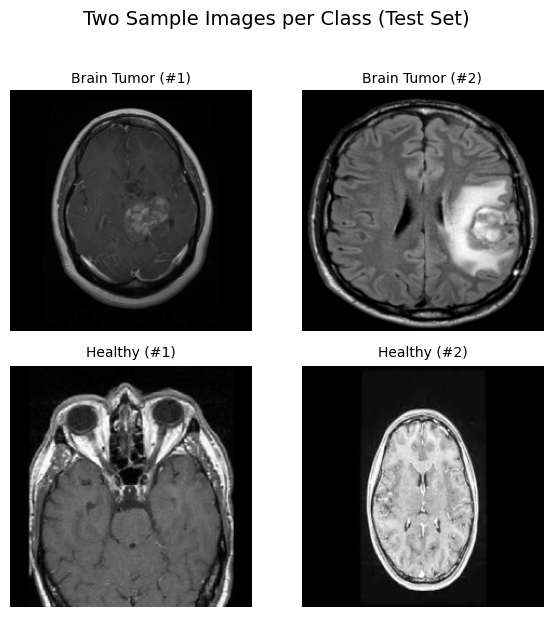

In [170]:
# Load all dataloaders to inspect sizes
train_loader, val_loader, classes = get_dataloaders(config.DATA_PATH, config.BATCH_SIZE, config.IMAGE_SIZE)
test_loader, _ = get_test_dataloader(config.DATA_PATH, config.BATCH_SIZE, config.IMAGE_SIZE)

# --- Display Dataset Sample Counts ---
print("\n================ DATASET SIZES ================")
print(f"Train Dataset      : {len(train_loader.dataset)} samples ({len(train_loader)} batches)")
print(f"Validation Dataset : {len(val_loader.dataset)} samples ({len(val_loader)} batches)")
print(f"Test Dataset       : {len(test_loader.dataset)} samples ({len(test_loader)} batches)")
print(f"Class Categories   : {classes}")
print("================================================")

# --- Display Visual Samples from Test Set ---
print("\nVisualizing samples from the test dataset...")
show_test_samples(test_loader, classes)

Training with seed: 42
-> Saved new best model at epoch 1 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [1/25] | Train Loss: 0.4309 | Val Loss: 0.2553 | Val Acc: 0.9040
-> Saved new best model at epoch 2 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [2/25] | Train Loss: 0.1830 | Val Loss: 0.1513 | Val Acc: 0.9439
-> Saved new best model at epoch 3 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [3/25] | Train Loss: 0.1072 | Val Loss: 0.1094 | Val Acc: 0.9675
Epoch [4/25] | Train Loss: 0.0876 | Val Loss: 0.1137 | Val Acc: 0.9631
Epoch [5/25] | Train Loss: 0.0657 | Val Loss: 0.1437 | Val Acc: 0.9453
-> Saved new best model at epoch 6 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [6/25] | Train Loss: 0.0542 | Val Loss: 0.0730 | Val Acc: 0.9808
Epoch [7/25] | Train Loss: 0.0546 | Val Loss: 0.0873 | Val Acc: 0.9793
Epoch [8/25] | Train Loss: 0.0427 | Val Loss: 0.1267 | Val Acc: 0.9513
-> Saved new best model at epoch 9 to ./output/braintumor/best_brain_

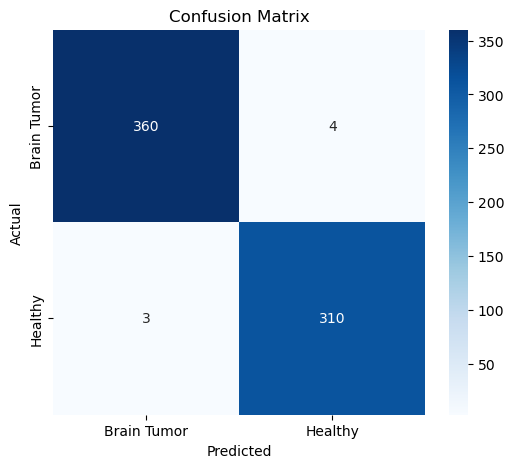

{'accuracy': 0.9896602658788775, 'macro_f1': 0.9896035574744038, 'weighted_f1': 0.9896614000469669, 'mcc': 0.9792114805168168}
Successfully loaded model weights from ./output/braintumor/best_brain_tumor_model.pth

--- Test Dataset Evaluation Results ---
Accuracy: 0.9912 | Macro F1: 0.9911 | Weighted F1: 0.9912 | MCC: 0.9823


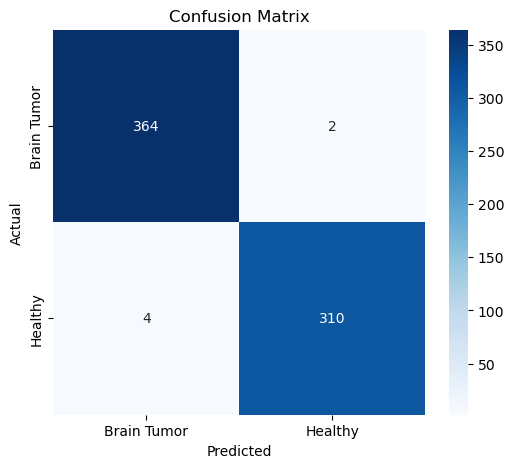

Training with seed: 123
-> Saved new best model at epoch 1 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [1/25] | Train Loss: 0.4196 | Val Loss: 0.2224 | Val Acc: 0.9217
-> Saved new best model at epoch 2 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [2/25] | Train Loss: 0.1842 | Val Loss: 0.2007 | Val Acc: 0.9335
-> Saved new best model at epoch 3 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [3/25] | Train Loss: 0.1156 | Val Loss: 0.1192 | Val Acc: 0.9572
Epoch [4/25] | Train Loss: 0.0842 | Val Loss: 0.1209 | Val Acc: 0.9734
Epoch [5/25] | Train Loss: 0.0669 | Val Loss: 0.1234 | Val Acc: 0.9513
-> Saved new best model at epoch 6 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [6/25] | Train Loss: 0.0532 | Val Loss: 0.0869 | Val Acc: 0.9808
-> Saved new best model at epoch 7 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [7/25] | Train Loss: 0.0405 | Val Loss: 0.0662 | Val Acc: 0.9852
Epoch [8/25] | Train Loss: 0.0400 | Val Loss: 0.1879 |

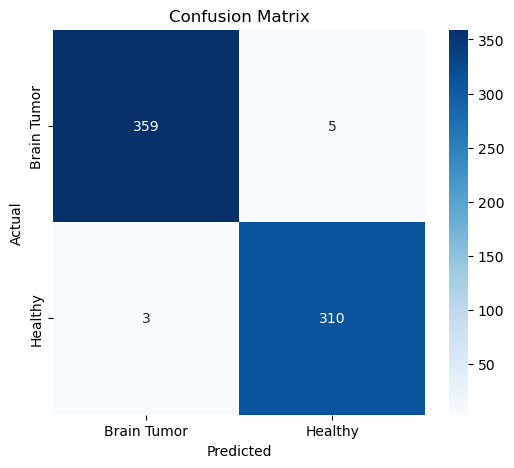

{'accuracy': 0.9881831610044313, 'macro_f1': 0.9881209313751294, 'weighted_f1': 0.9881857009893009, 'mcc': 0.9762592913065303}
Successfully loaded model weights from ./output/braintumor/best_brain_tumor_model.pth

--- Test Dataset Evaluation Results ---
Accuracy: 0.9779 | Macro F1: 0.9778 | Weighted F1: 0.9779 | MCC: 0.9557


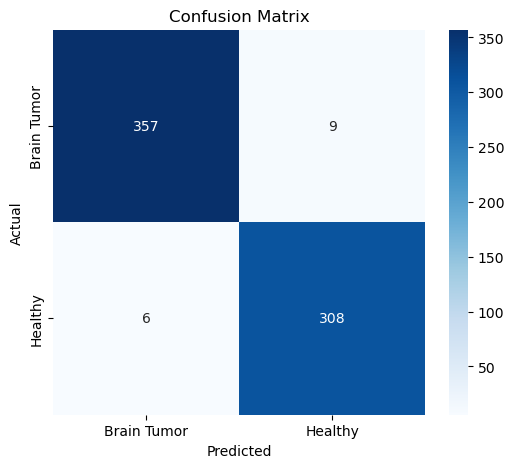

Training with seed: 456
-> Saved new best model at epoch 1 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [1/25] | Train Loss: 0.4407 | Val Loss: 0.2045 | Val Acc: 0.9291
-> Saved new best model at epoch 2 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [2/25] | Train Loss: 0.1828 | Val Loss: 0.1314 | Val Acc: 0.9601
-> Saved new best model at epoch 3 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [3/25] | Train Loss: 0.1169 | Val Loss: 0.1131 | Val Acc: 0.9631
-> Saved new best model at epoch 4 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [4/25] | Train Loss: 0.0825 | Val Loss: 0.0887 | Val Acc: 0.9705
-> Saved new best model at epoch 5 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [5/25] | Train Loss: 0.0594 | Val Loss: 0.0631 | Val Acc: 0.9838
Epoch [6/25] | Train Loss: 0.0629 | Val Loss: 0.1291 | Val Acc: 0.9823
Epoch [7/25] | Train Loss: 0.0496 | Val Loss: 0.0793 | Val Acc: 0.9808
Epoch [8/25] | Train Loss: 0.0359 | Val Loss: 0.0975 |

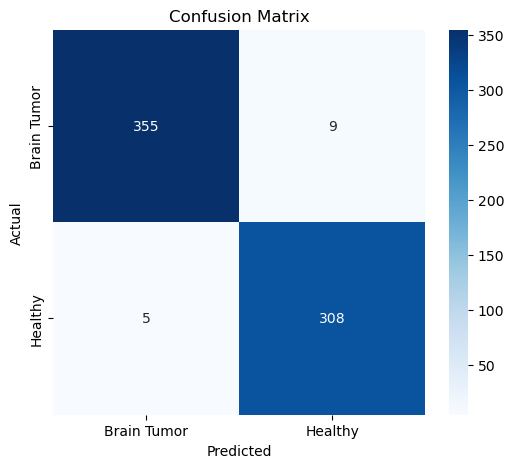

{'accuracy': 0.9793205317577548, 'macro_f1': 0.979220380601596, 'weighted_f1': 0.9793290552604067, 'mcc': 0.9585097884517086}
Successfully loaded model weights from ./output/braintumor/best_brain_tumor_model.pth

--- Test Dataset Evaluation Results ---
Accuracy: 0.9868 | Macro F1: 0.9867 | Weighted F1: 0.9868 | MCC: 0.9734


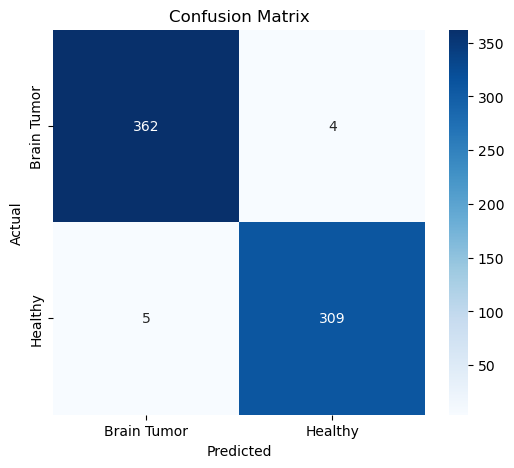

Training with seed: 789
-> Saved new best model at epoch 1 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [1/25] | Train Loss: 0.4347 | Val Loss: 0.2175 | Val Acc: 0.9202
-> Saved new best model at epoch 2 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [2/25] | Train Loss: 0.1752 | Val Loss: 0.1682 | Val Acc: 0.9306
-> Saved new best model at epoch 3 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [3/25] | Train Loss: 0.1167 | Val Loss: 0.1517 | Val Acc: 0.9350
-> Saved new best model at epoch 4 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [4/25] | Train Loss: 0.0875 | Val Loss: 0.1382 | Val Acc: 0.9483
-> Saved new best model at epoch 5 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [5/25] | Train Loss: 0.0630 | Val Loss: 0.1373 | Val Acc: 0.9513
-> Saved new best model at epoch 6 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [6/25] | Train Loss: 0.0646 | Val Loss: 0.1335 | Val Acc: 0.9453
-> Saved new best model at epoch 7 to ./

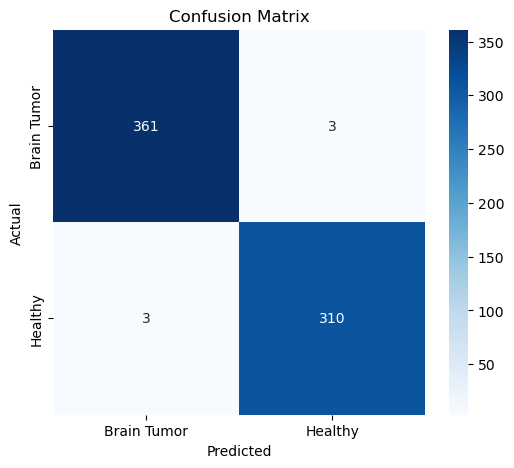

{'accuracy': 0.9911373707533235, 'macro_f1': 0.9910867886107503, 'weighted_f1': 0.9911373707533235, 'mcc': 0.9821735772215006}
Successfully loaded model weights from ./output/braintumor/best_brain_tumor_model.pth

--- Test Dataset Evaluation Results ---
Accuracy: 0.9809 | Macro F1: 0.9808 | Weighted F1: 0.9809 | MCC: 0.9616


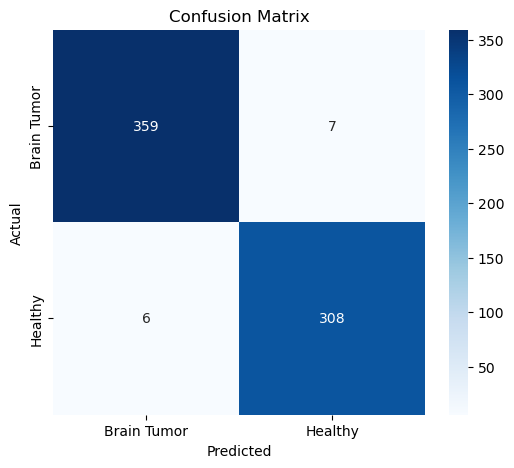

Training with seed: 2026
-> Saved new best model at epoch 1 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [1/25] | Train Loss: 0.4268 | Val Loss: 0.2215 | Val Acc: 0.9217
-> Saved new best model at epoch 2 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [2/25] | Train Loss: 0.1787 | Val Loss: 0.1794 | Val Acc: 0.9247
-> Saved new best model at epoch 3 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [3/25] | Train Loss: 0.1139 | Val Loss: 0.1016 | Val Acc: 0.9601
Epoch [4/25] | Train Loss: 0.0826 | Val Loss: 0.1612 | Val Acc: 0.9335
-> Saved new best model at epoch 5 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [5/25] | Train Loss: 0.0725 | Val Loss: 0.0978 | Val Acc: 0.9675
-> Saved new best model at epoch 6 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [6/25] | Train Loss: 0.0575 | Val Loss: 0.0949 | Val Acc: 0.9764
-> Saved new best model at epoch 7 to ./output/braintumor/best_brain_tumor_model.pth
Epoch [7/25] | Train Loss: 0.0445 | Val

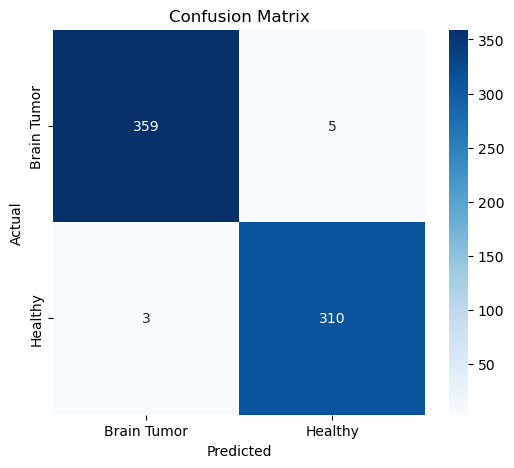

{'accuracy': 0.9881831610044313, 'macro_f1': 0.9881209313751294, 'weighted_f1': 0.9881857009893009, 'mcc': 0.9762592913065303}
Successfully loaded model weights from ./output/braintumor/best_brain_tumor_model.pth

--- Test Dataset Evaluation Results ---
Accuracy: 0.9824 | Macro F1: 0.9822 | Weighted F1: 0.9824 | MCC: 0.9645


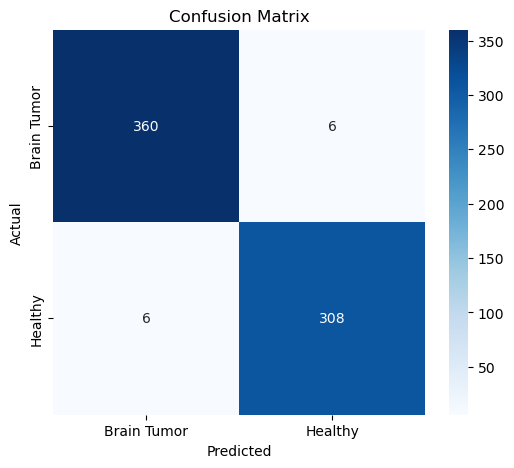

In [78]:
metrics = []
for seed in [42, 123, 456, 789, 2026]:
    print("Training with seed:", seed)
    set_seed(seed)
    print(train(config))
    metric = run_test(config)
    updated_metric = {"seed": seed} | metric
    metrics.append(updated_metric)

In [79]:
import os
import pandas as pd
df_run = pd.DataFrame(metrics)
df_run.to_csv(os.path.join(config.OUTPUT_DIR, 'metrics.csv'))

In [80]:
df_run

,seed,accuracy,macro_f1,weighted_f1,mcc
0,42,0.991176,0.991120,0.991174,0.982258
1,123,0.977941,0.977826,0.977948,0.955691
2,456,0.986765,0.986684,0.986763,0.973372
3,789,0.980882,0.980774,0.980884,0.961553
4,2026,0.982353,0.982249,0.982353,0.964498


In [81]:
df_run.describe()

,seed,accuracy,macro_f1,weighted_f1,mcc
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,687.200000,0.983824,0.983731,0.983825,0.967474
std,804.799167,0.005199,0.005223,0.005196,0.010442
min,42.000000,0.977941,0.977826,0.977948,0.955691
25%,123.000000,0.980882,0.980774,0.980884,0.961553
50%,456.000000,0.982353,0.982249,0.982353,0.964498
75%,789.000000,0.986765,0.986684,0.986763,0.973372
max,2026.000000,0.991176,0.991120,0.991174,0.982258


In [104]:
# load the best model
model_path = config.MODEL_SAVE_PATH
model = get_medical_cnn(config.NUM_CLASSES, config.MODEL_NAME).to(config.DEVICE)
state_dict = torch.load(config.MODEL_SAVE_PATH, map_location=config.DEVICE)
model.load_state_dict(state_dict)
model.eval()
print("Model loaded successfully!")

Model loaded successfully!



--- Evaluating on Clean Test Data ---
Accuracy: 0.9824 | Macro F1: 0.9822 | Weighted F1: 0.9824 | MCC: 0.9645


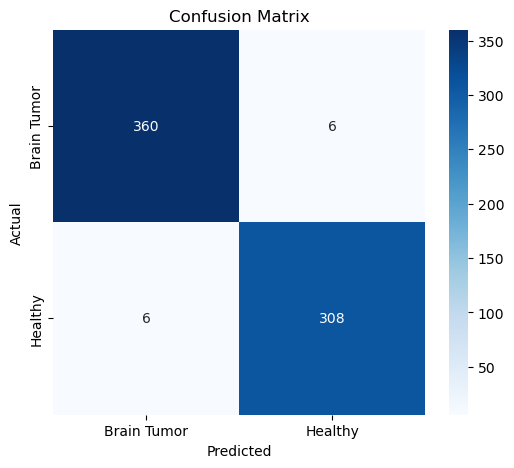


--- Running FGSM Attack (Epsilon: 0.0078) ---
[FGSM_eps_0.0078] Generation Time: 2.9676 seconds
Accuracy: 0.8632 | Macro F1: 0.8631 | Weighted F1: 0.8634 | MCC: 0.7298


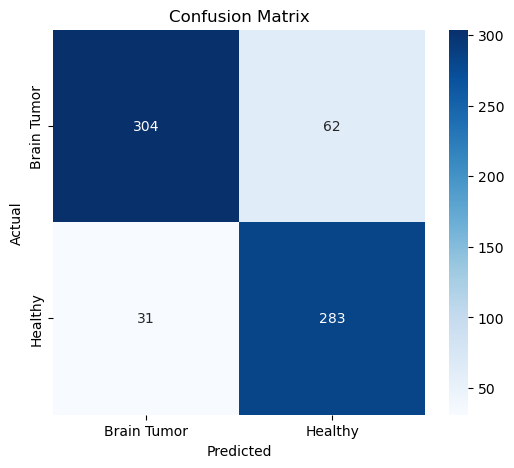


--- Running FGSM Attack (Epsilon: 0.0157) ---
[FGSM_eps_0.0157] Generation Time: 2.9660 seconds
Accuracy: 0.7588 | Macro F1: 0.7568 | Weighted F1: 0.7585 | MCC: 0.5139


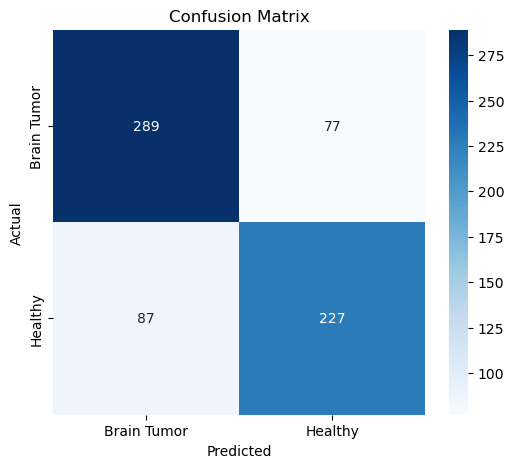


--- Running FGSM Attack (Epsilon: 0.0314) ---
[FGSM_eps_0.0314] Generation Time: 2.9735 seconds
Accuracy: 0.4603 | Macro F1: 0.4450 | Weighted F1: 0.4379 | MCC: -0.0529


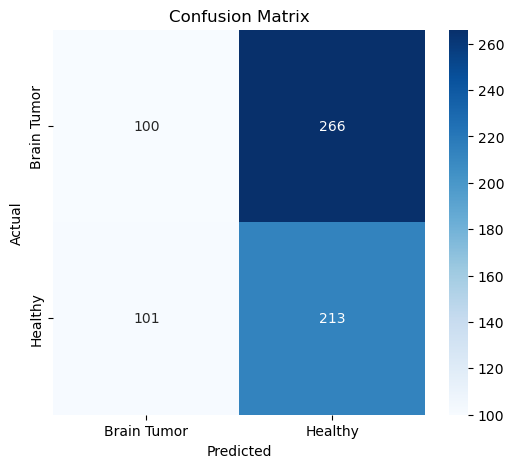


--- Running FGSM Attack (Epsilon: 0.0627) ---
[FGSM_eps_0.0627] Generation Time: 2.9545 seconds
Accuracy: 0.4647 | Macro F1: 0.4646 | Weighted F1: 0.4642 | MCC: -0.0634


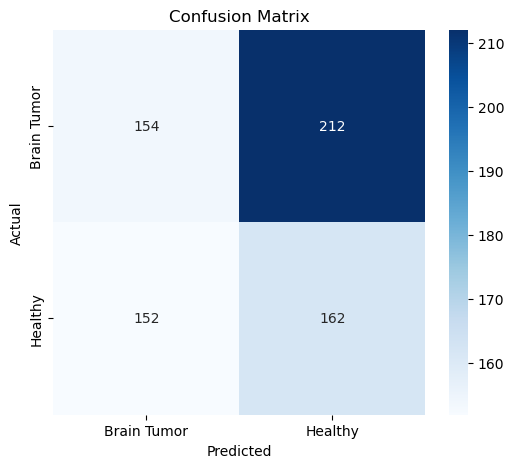


--- Running FGSM Attack (Epsilon: 0.1255) ---
[FGSM_eps_0.1255] Generation Time: 2.9722 seconds
Accuracy: 0.5382 | Macro F1: 0.3499 | Weighted F1: 0.3767 | MCC: 0.0000


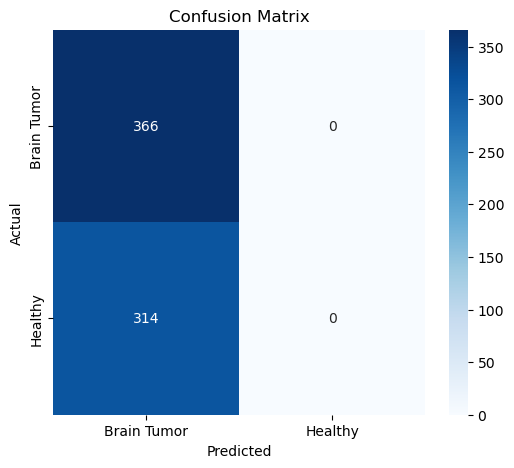


--- Running FGSM Attack (Epsilon: 0.2510) ---
[FGSM_eps_0.2510] Generation Time: 2.9661 seconds
Accuracy: 0.5382 | Macro F1: 0.3499 | Weighted F1: 0.3767 | MCC: 0.0000


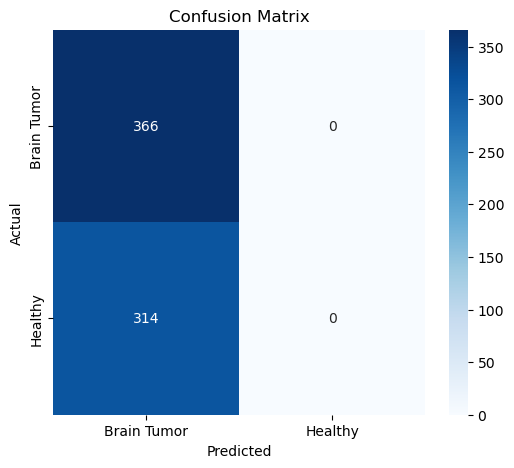


--- Running MI-FGSM Attack (Epsilon: 0.0078) ---
[MI-FGSM_eps_0.0078] Generation Time: 19.6535 seconds
Accuracy: 0.7294 | Macro F1: 0.7188 | Weighted F1: 0.7230 | MCC: 0.4591


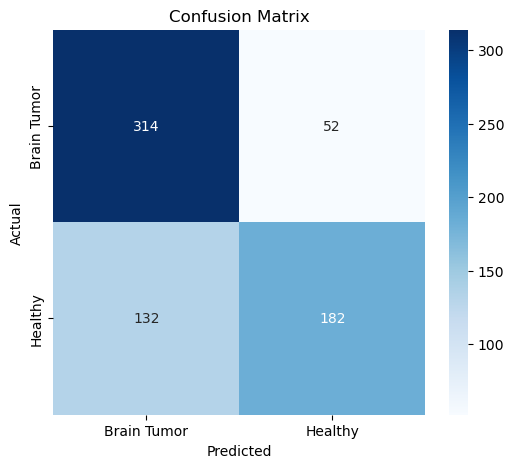


--- Running MI-FGSM Attack (Epsilon: 0.0157) ---
[MI-FGSM_eps_0.0157] Generation Time: 19.7817 seconds
Accuracy: 0.5368 | Macro F1: 0.4997 | Weighted F1: 0.5101 | MCC: 0.0429


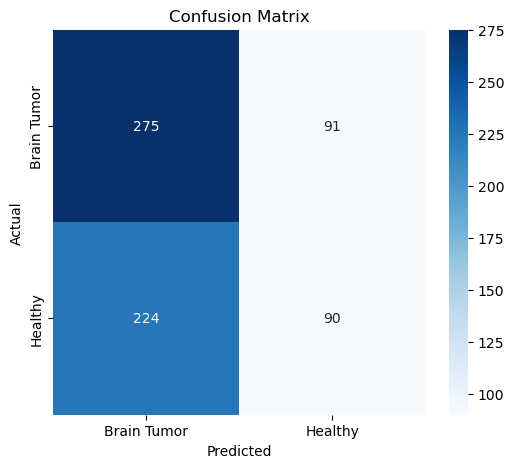


--- Running MI-FGSM Attack (Epsilon: 0.0314) ---
[MI-FGSM_eps_0.0314] Generation Time: 19.9503 seconds
Accuracy: 0.4221 | Macro F1: 0.3859 | Weighted F1: 0.3745 | MCC: -0.1369


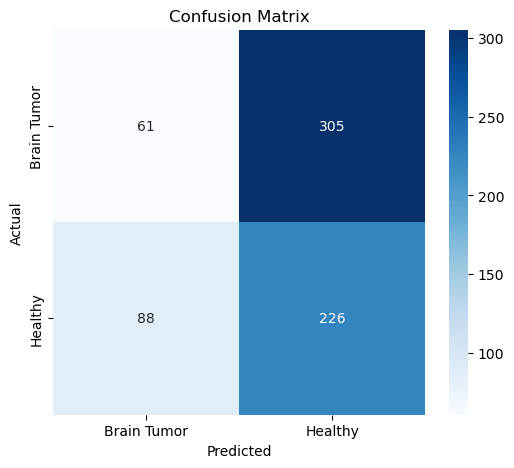


--- Running MI-FGSM Attack (Epsilon: 0.0627) ---
[MI-FGSM_eps_0.0627] Generation Time: 20.0531 seconds
Accuracy: 0.5544 | Macro F1: 0.5145 | Weighted F1: 0.5251 | MCC: 0.0818


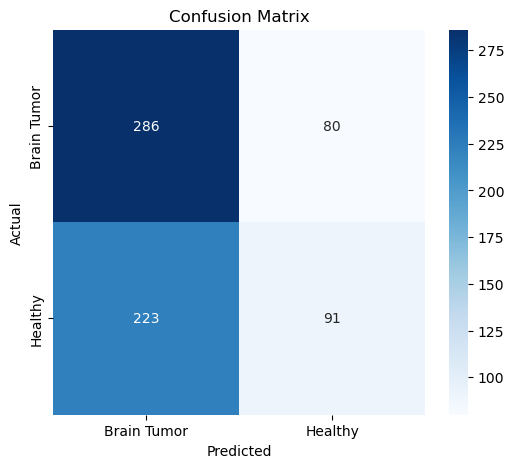


--- Running MI-FGSM Attack (Epsilon: 0.1255) ---
[MI-FGSM_eps_0.1255] Generation Time: 20.1769 seconds
Accuracy: 0.4868 | Macro F1: 0.4829 | Weighted F1: 0.4863 | MCC: -0.0342


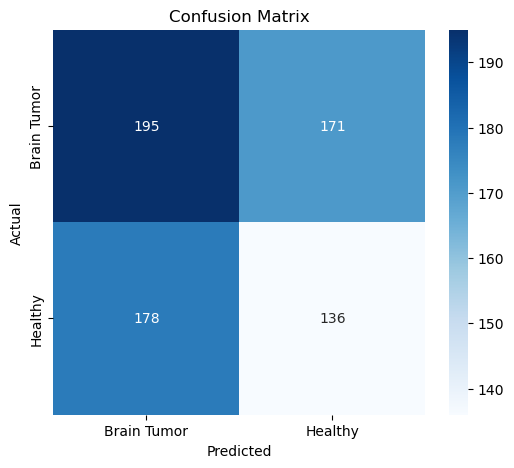


--- Running MI-FGSM Attack (Epsilon: 0.2510) ---
[MI-FGSM_eps_0.2510] Generation Time: 20.1947 seconds
Accuracy: 0.4868 | Macro F1: 0.4829 | Weighted F1: 0.4863 | MCC: -0.0342


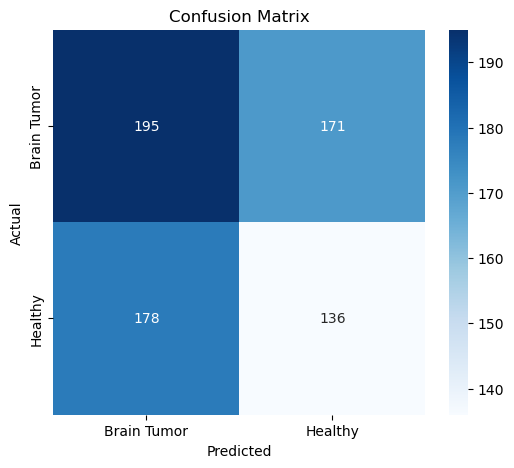


--- Running NIFGSM Attack (Epsilon: 0.0078) ---
[NIFGSM_eps_0.0078] Generation Time: 20.2222 seconds
Accuracy: 0.7809 | Macro F1: 0.7744 | Weighted F1: 0.7773 | MCC: 0.5630


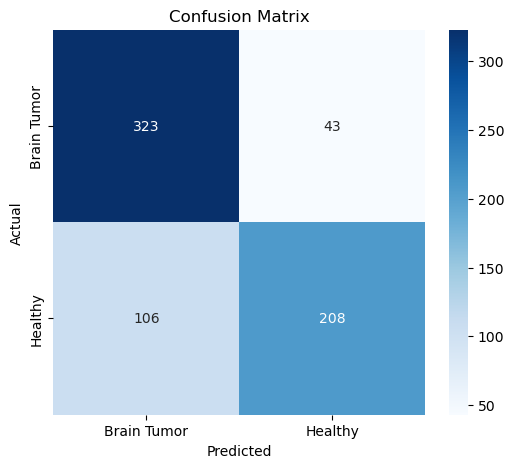


--- Running NIFGSM Attack (Epsilon: 0.0157) ---
[NIFGSM_eps_0.0157] Generation Time: 20.2747 seconds
Accuracy: 0.4103 | Macro F1: 0.3526 | Weighted F1: 0.3674 | MCC: -0.2575


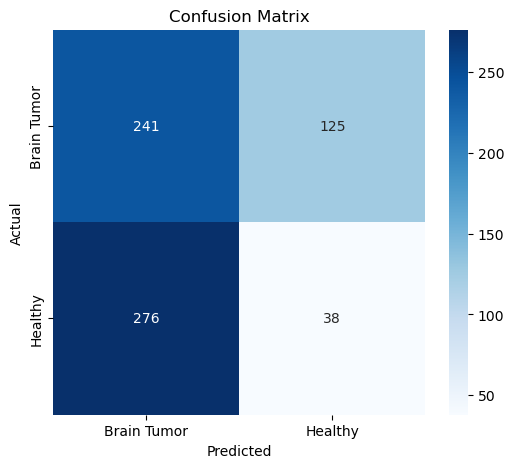


--- Running NIFGSM Attack (Epsilon: 0.0314) ---
[NIFGSM_eps_0.0314] Generation Time: 20.3733 seconds
Accuracy: 0.2779 | Macro F1: 0.2629 | Weighted F1: 0.2549 | MCC: -0.4480


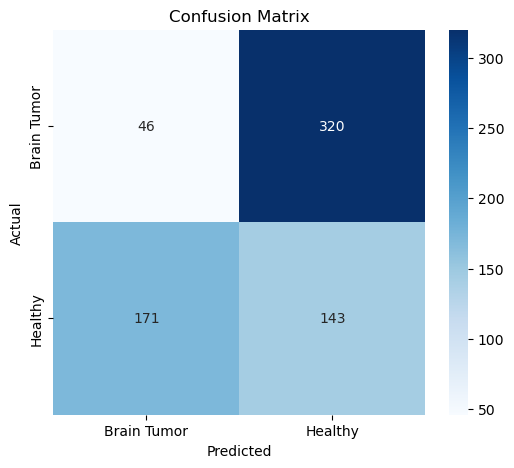


--- Running NIFGSM Attack (Epsilon: 0.0627) ---
[NIFGSM_eps_0.0627] Generation Time: 20.4729 seconds
Accuracy: 0.5397 | Macro F1: 0.4927 | Weighted F1: 0.5045 | MCC: 0.0459


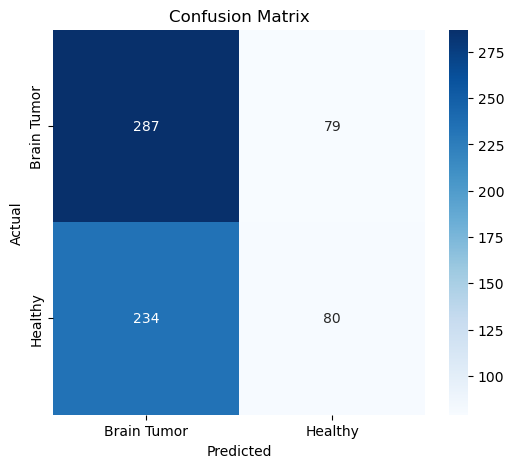


--- Running NIFGSM Attack (Epsilon: 0.1255) ---
[NIFGSM_eps_0.1255] Generation Time: 20.3808 seconds
Accuracy: 0.4779 | Macro F1: 0.4760 | Weighted F1: 0.4785 | MCC: -0.0477


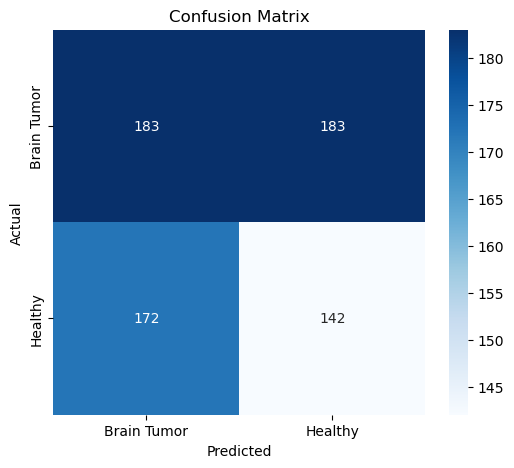


--- Running NIFGSM Attack (Epsilon: 0.2510) ---
[NIFGSM_eps_0.2510] Generation Time: 20.4191 seconds
Accuracy: 0.4779 | Macro F1: 0.4760 | Weighted F1: 0.4785 | MCC: -0.0477


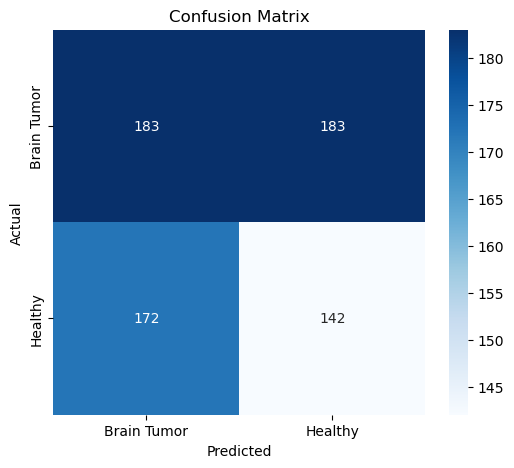


--- Running RFGSM Attack (Epsilon: 0.0078) ---
[RFGSM_eps_0.0078] Generation Time: 20.3394 seconds
Accuracy: 0.8529 | Macro F1: 0.8517 | Weighted F1: 0.8527 | MCC: 0.7038


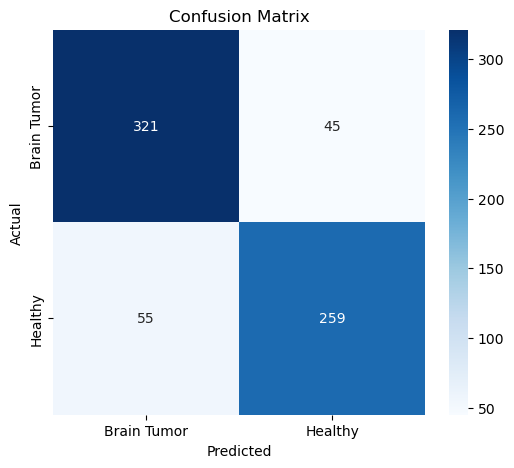


--- Running RFGSM Attack (Epsilon: 0.0157) ---
[RFGSM_eps_0.0157] Generation Time: 20.3767 seconds
Accuracy: 0.6132 | Macro F1: 0.5837 | Weighted F1: 0.5922 | MCC: 0.2159


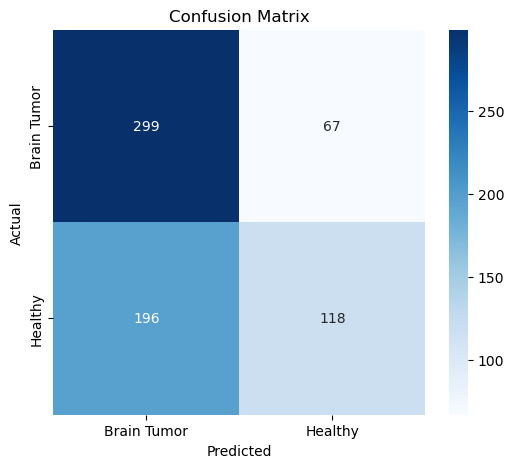


--- Running RFGSM Attack (Epsilon: 0.0314) ---
[RFGSM_eps_0.0314] Generation Time: 20.3967 seconds
Accuracy: 0.4176 | Macro F1: 0.4147 | Weighted F1: 0.4179 | MCC: -0.1705


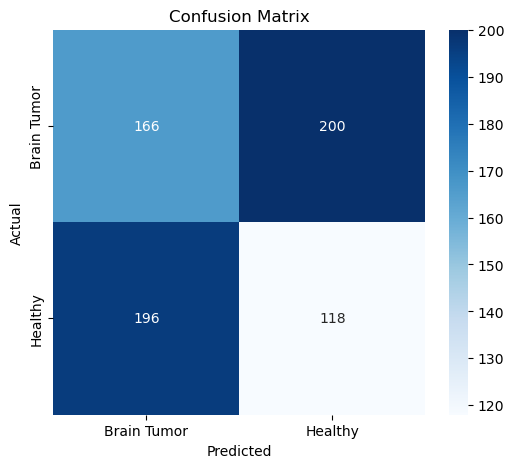


--- Running RFGSM Attack (Epsilon: 0.0627) ---
[RFGSM_eps_0.0627] Generation Time: 20.4810 seconds
Accuracy: 0.4015 | Macro F1: 0.3937 | Weighted F1: 0.3884 | MCC: -0.1830


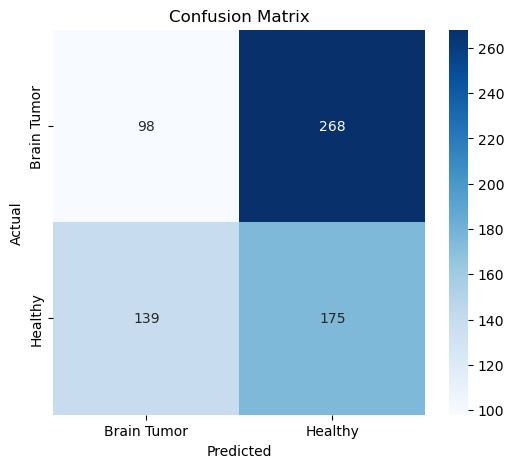


--- Running RFGSM Attack (Epsilon: 0.1255) ---
[RFGSM_eps_0.1255] Generation Time: 20.6021 seconds
Accuracy: 0.4176 | Macro F1: 0.4099 | Weighted F1: 0.4047 | MCC: -0.1489


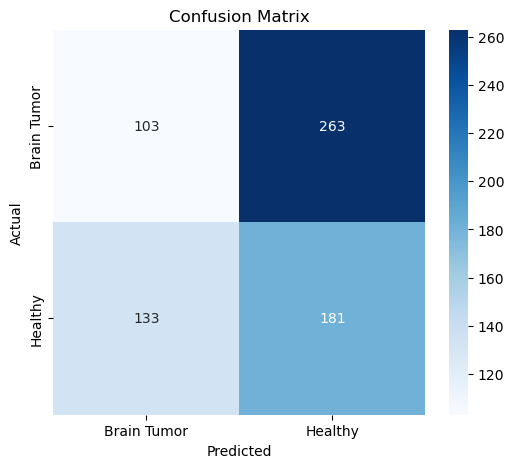


--- Running RFGSM Attack (Epsilon: 0.2510) ---
[RFGSM_eps_0.2510] Generation Time: 20.6287 seconds
Accuracy: 0.3926 | Macro F1: 0.3839 | Weighted F1: 0.3783 | MCC: -0.2014


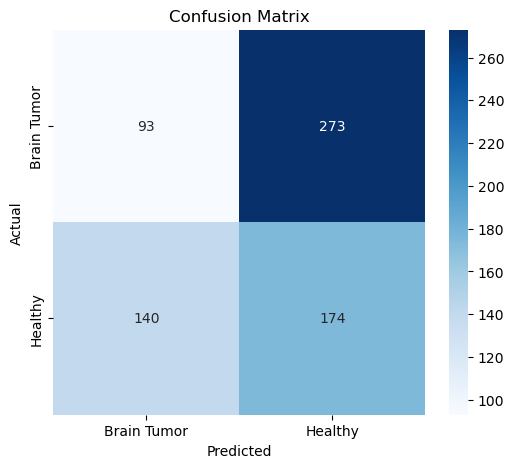


--- Running PGDL2 Attack (Epsilon: 0.0078) ---
[PGDL2_eps_0.0078] Generation Time: 20.6224 seconds
Accuracy: 0.9853 | Macro F1: 0.9852 | Weighted F1: 0.9853 | MCC: 0.9704


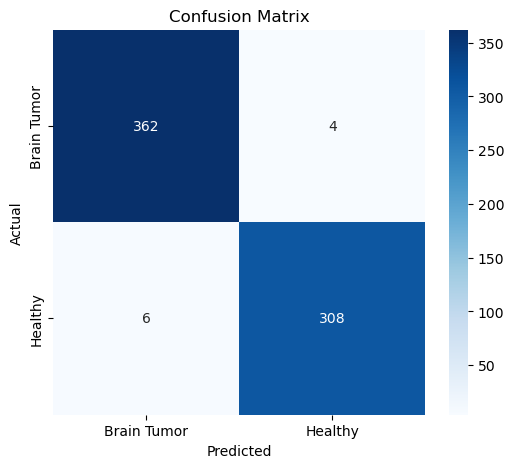


--- Running PGDL2 Attack (Epsilon: 0.0157) ---
[PGDL2_eps_0.0157] Generation Time: 20.6762 seconds
Accuracy: 0.9853 | Macro F1: 0.9852 | Weighted F1: 0.9853 | MCC: 0.9704


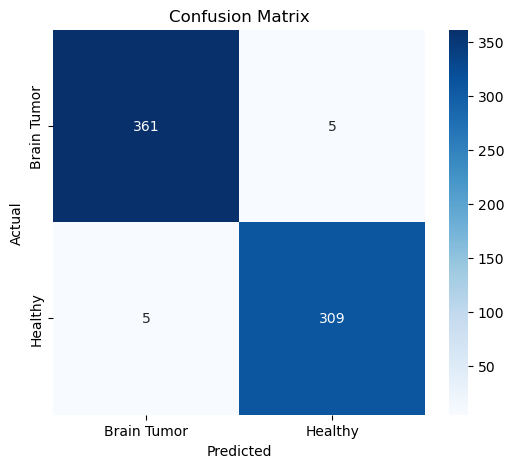


--- Running PGDL2 Attack (Epsilon: 0.0314) ---
[PGDL2_eps_0.0314] Generation Time: 20.7164 seconds
Accuracy: 0.9838 | Macro F1: 0.9837 | Weighted F1: 0.9838 | MCC: 0.9675


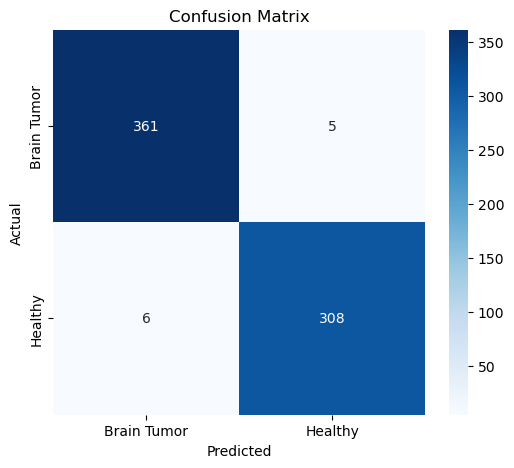


--- Running PGDL2 Attack (Epsilon: 0.0627) ---
[PGDL2_eps_0.0627] Generation Time: 20.8398 seconds
Accuracy: 0.9779 | Macro F1: 0.9778 | Weighted F1: 0.9779 | MCC: 0.9556


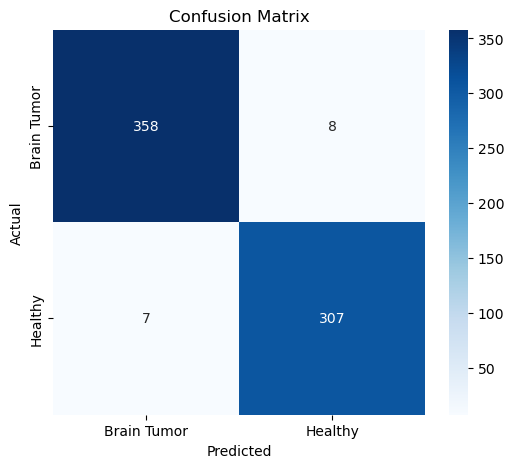


--- Running PGDL2 Attack (Epsilon: 0.1255) ---
[PGDL2_eps_0.1255] Generation Time: 20.7796 seconds
Accuracy: 0.9691 | Macro F1: 0.9690 | Weighted F1: 0.9691 | MCC: 0.9380


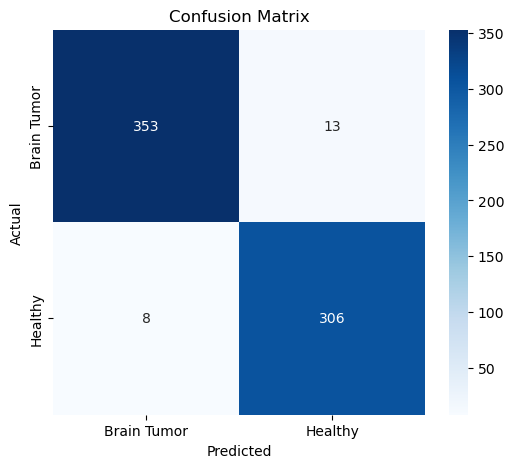


--- Running PGDL2 Attack (Epsilon: 0.2510) ---
[PGDL2_eps_0.2510] Generation Time: 20.8109 seconds
Accuracy: 0.9603 | Macro F1: 0.9600 | Weighted F1: 0.9603 | MCC: 0.9201


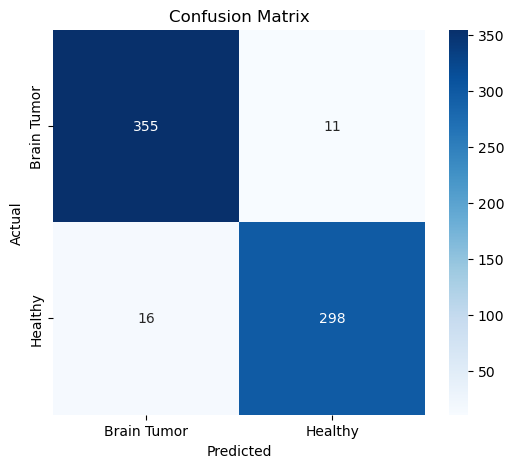


--- Running PGD Attack (Epsilon: 0.0078) ---
[PGD_eps_0.0078] Generation Time: 79.8809 seconds
Accuracy: 0.8471 | Macro F1: 0.8456 | Weighted F1: 0.8468 | MCC: 0.6919


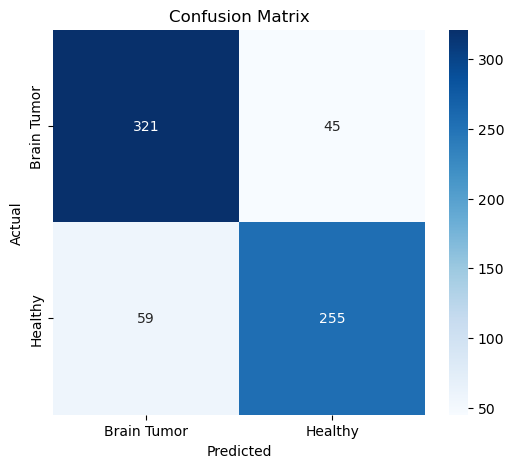


--- Running PGD Attack (Epsilon: 0.0157) ---
[PGD_eps_0.0157] Generation Time: 80.0630 seconds
Accuracy: 0.6059 | Macro F1: 0.5755 | Weighted F1: 0.5842 | MCC: 0.1994


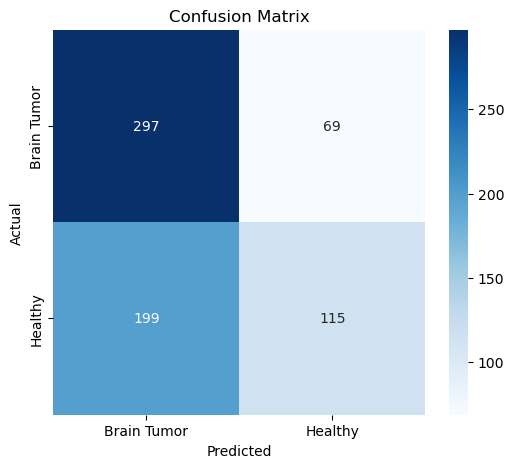


--- Running PGD Attack (Epsilon: 0.0314) ---
[PGD_eps_0.0314] Generation Time: 79.8418 seconds
Accuracy: 0.3029 | Macro F1: 0.3008 | Weighted F1: 0.3037 | MCC: -0.3982


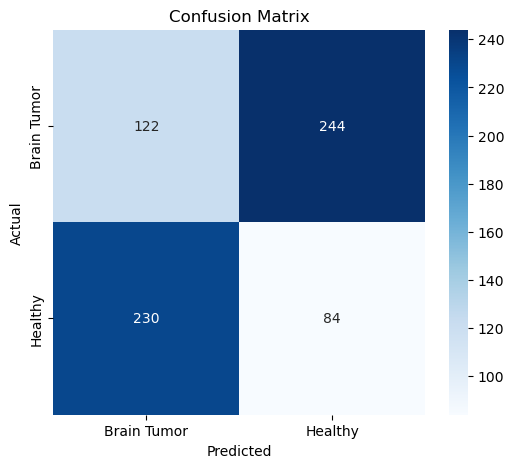


--- Running PGD Attack (Epsilon: 0.0627) ---
[PGD_eps_0.0627] Generation Time: 79.6417 seconds
Accuracy: 0.4235 | Macro F1: 0.4219 | Weighted F1: 0.4242 | MCC: -0.1557


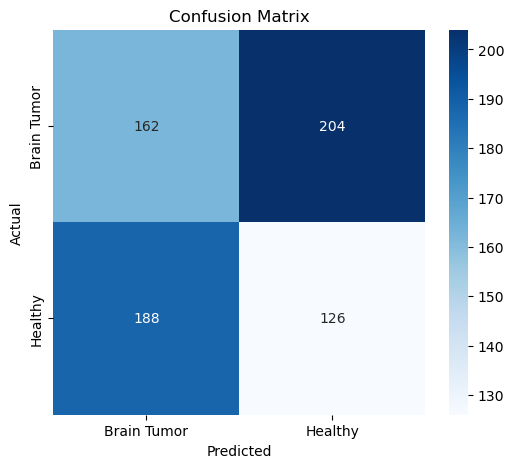


--- Running PGD Attack (Epsilon: 0.1255) ---
[PGD_eps_0.1255] Generation Time: 79.5655 seconds
Accuracy: 0.5441 | Macro F1: 0.4144 | Weighted F1: 0.4355 | MCC: 0.0442


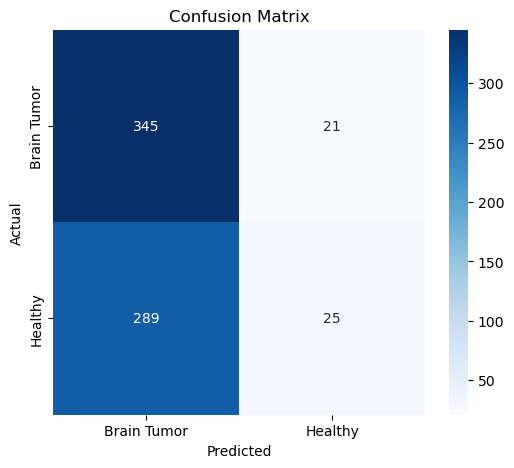


--- Running PGD Attack (Epsilon: 0.2510) ---
[PGD_eps_0.2510] Generation Time: 79.4616 seconds
Accuracy: 0.5368 | Macro F1: 0.4832 | Weighted F1: 0.4959 | MCC: 0.0367


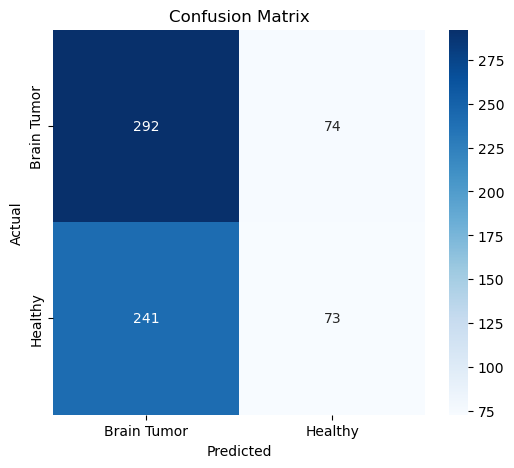


================ MULTI-EPSILON ADVERSARIAL REPORT ================
Experiment             | Time (s)   | Accuracy   | Macro F1   | MCC       
----------------------------------------------------------------------
Clean Baseline         | 0.00       | 0.9824     | 0.9822     | 0.9645    
FGSM_eps_0.0078        | 2.97       | 0.8632     | 0.8631     | 0.7298    
FGSM_eps_0.0157        | 2.97       | 0.7588     | 0.7568     | 0.5139    
FGSM_eps_0.0314        | 2.97       | 0.4603     | 0.4450     | -0.0529   
FGSM_eps_0.0627        | 2.95       | 0.4647     | 0.4646     | -0.0634   
FGSM_eps_0.1255        | 2.97       | 0.5382     | 0.3499     | 0.0000    
FGSM_eps_0.2510        | 2.97       | 0.5382     | 0.3499     | 0.0000    
MI-FGSM_eps_0.0078     | 19.65      | 0.7294     | 0.7188     | 0.4591    
MI-FGSM_eps_0.0157     | 19.78      | 0.5368     | 0.4997     | 0.0429    
MI-FGSM_eps_0.0314     | 19.95      | 0.4221     | 0.3859     | -0.1369   
MI-FGSM_eps_0.0627     | 20.05      

In [180]:
# Define a list of different epsilon values to explore
epsilon_values = [2/255, 4/255, 8/255, 16/255, 32/255, 64/255]

# Fetch the test_loader
test_loader, classes = get_test_dataloader(config.DATA_PATH, config.BATCH_SIZE, config.IMAGE_SIZE)

# Run evaluation suite across all epsilons
results, sample_cache = evaluate_attacks_with_eps(model, test_loader, classes, config.DEVICE, eps_list=epsilon_values)

# Print Summary Report
print("\n================ MULTI-EPSILON ADVERSARIAL REPORT ================")
print(f"{'Experiment':<22} | {'Time (s)':<10} | {'Accuracy':<10} | {'Macro F1':<10} | {'MCC':<10}")
print("-" * 70)

for key, data in results.items():
    if key == "Clean":
        m = data["metrics"]
        print(f"{'Clean Baseline':<22} | {data['time_seconds']:<10.2f} | {m['accuracy']:<10.4f} | {m['macro_f1']:<10.4f} | {m['mcc']:<10.4f}")
    else:
        m = data["metrics"]
        print(f"{key:<22} | {data['time_seconds']:<10.2f} | {m['accuracy']:<10.4f} | {m['macro_f1']:<10.4f} | {m['mcc']:<10.4f}")
print("==================================================================")

In [181]:
def convert_results_to_dataframe(results):
    """
    Flattens the nested results dictionary into a Pandas DataFrame.
    """
    rows = []
    for key, data in results.items():
        metrics = data["metrics"]
        
        if key == "Clean":
            row = {
                "Experiment": "Clean Baseline",
                "Attack": "None",
                "Epsilon": 0.0,
                "Time (s)": data["time_seconds"],
                "Accuracy": metrics.get("accuracy"),
                "Macro F1": metrics.get("macro_f1"),
                "Weighted F1": metrics.get("weighted_f1"),
                "MCC": metrics.get("mcc")
            }
        else:
            row = {
                "Experiment": key,
                "Attack": data["attack"],
                "Epsilon": data["epsilon"],
                "Time (s)": data["time_seconds"],
                "Accuracy": metrics.get("accuracy"),
                "Macro F1": metrics.get("macro_f1"),
                "Weighted F1": metrics.get("weighted_f1"),
                "MCC": metrics.get("mcc")
            }
        rows.append(row)
        
    df = pd.DataFrame(rows)
    return df

In [182]:
results_df = convert_results_to_dataframe(results)
results_df.to_csv(os.path.join(config.OUTPUT_DIR,'adversarial_result.csv'), index=False)

In [184]:
results_df.head()

,Experiment,Attack,Epsilon,Time (s),Accuracy,Macro F1,Weighted F1,MCC
0,Clean Baseline,None,0.000000,0.000000,0.982353,0.982249,0.982353,0.964498
1,FGSM_eps_0.0078,FGSM,0.007843,2.967614,0.863235,0.863105,0.863428,0.729811
2,FGSM_eps_0.0157,FGSM,0.015686,2.965970,0.758824,0.756802,0.758497,0.513936
3,FGSM_eps_0.0314,FGSM,0.031373,2.973508,0.460294,0.444967,0.437914,-0.052914
4,FGSM_eps_0.0627,FGSM,0.062745,2.954496,0.464706,0.464632,0.464150,-0.063444


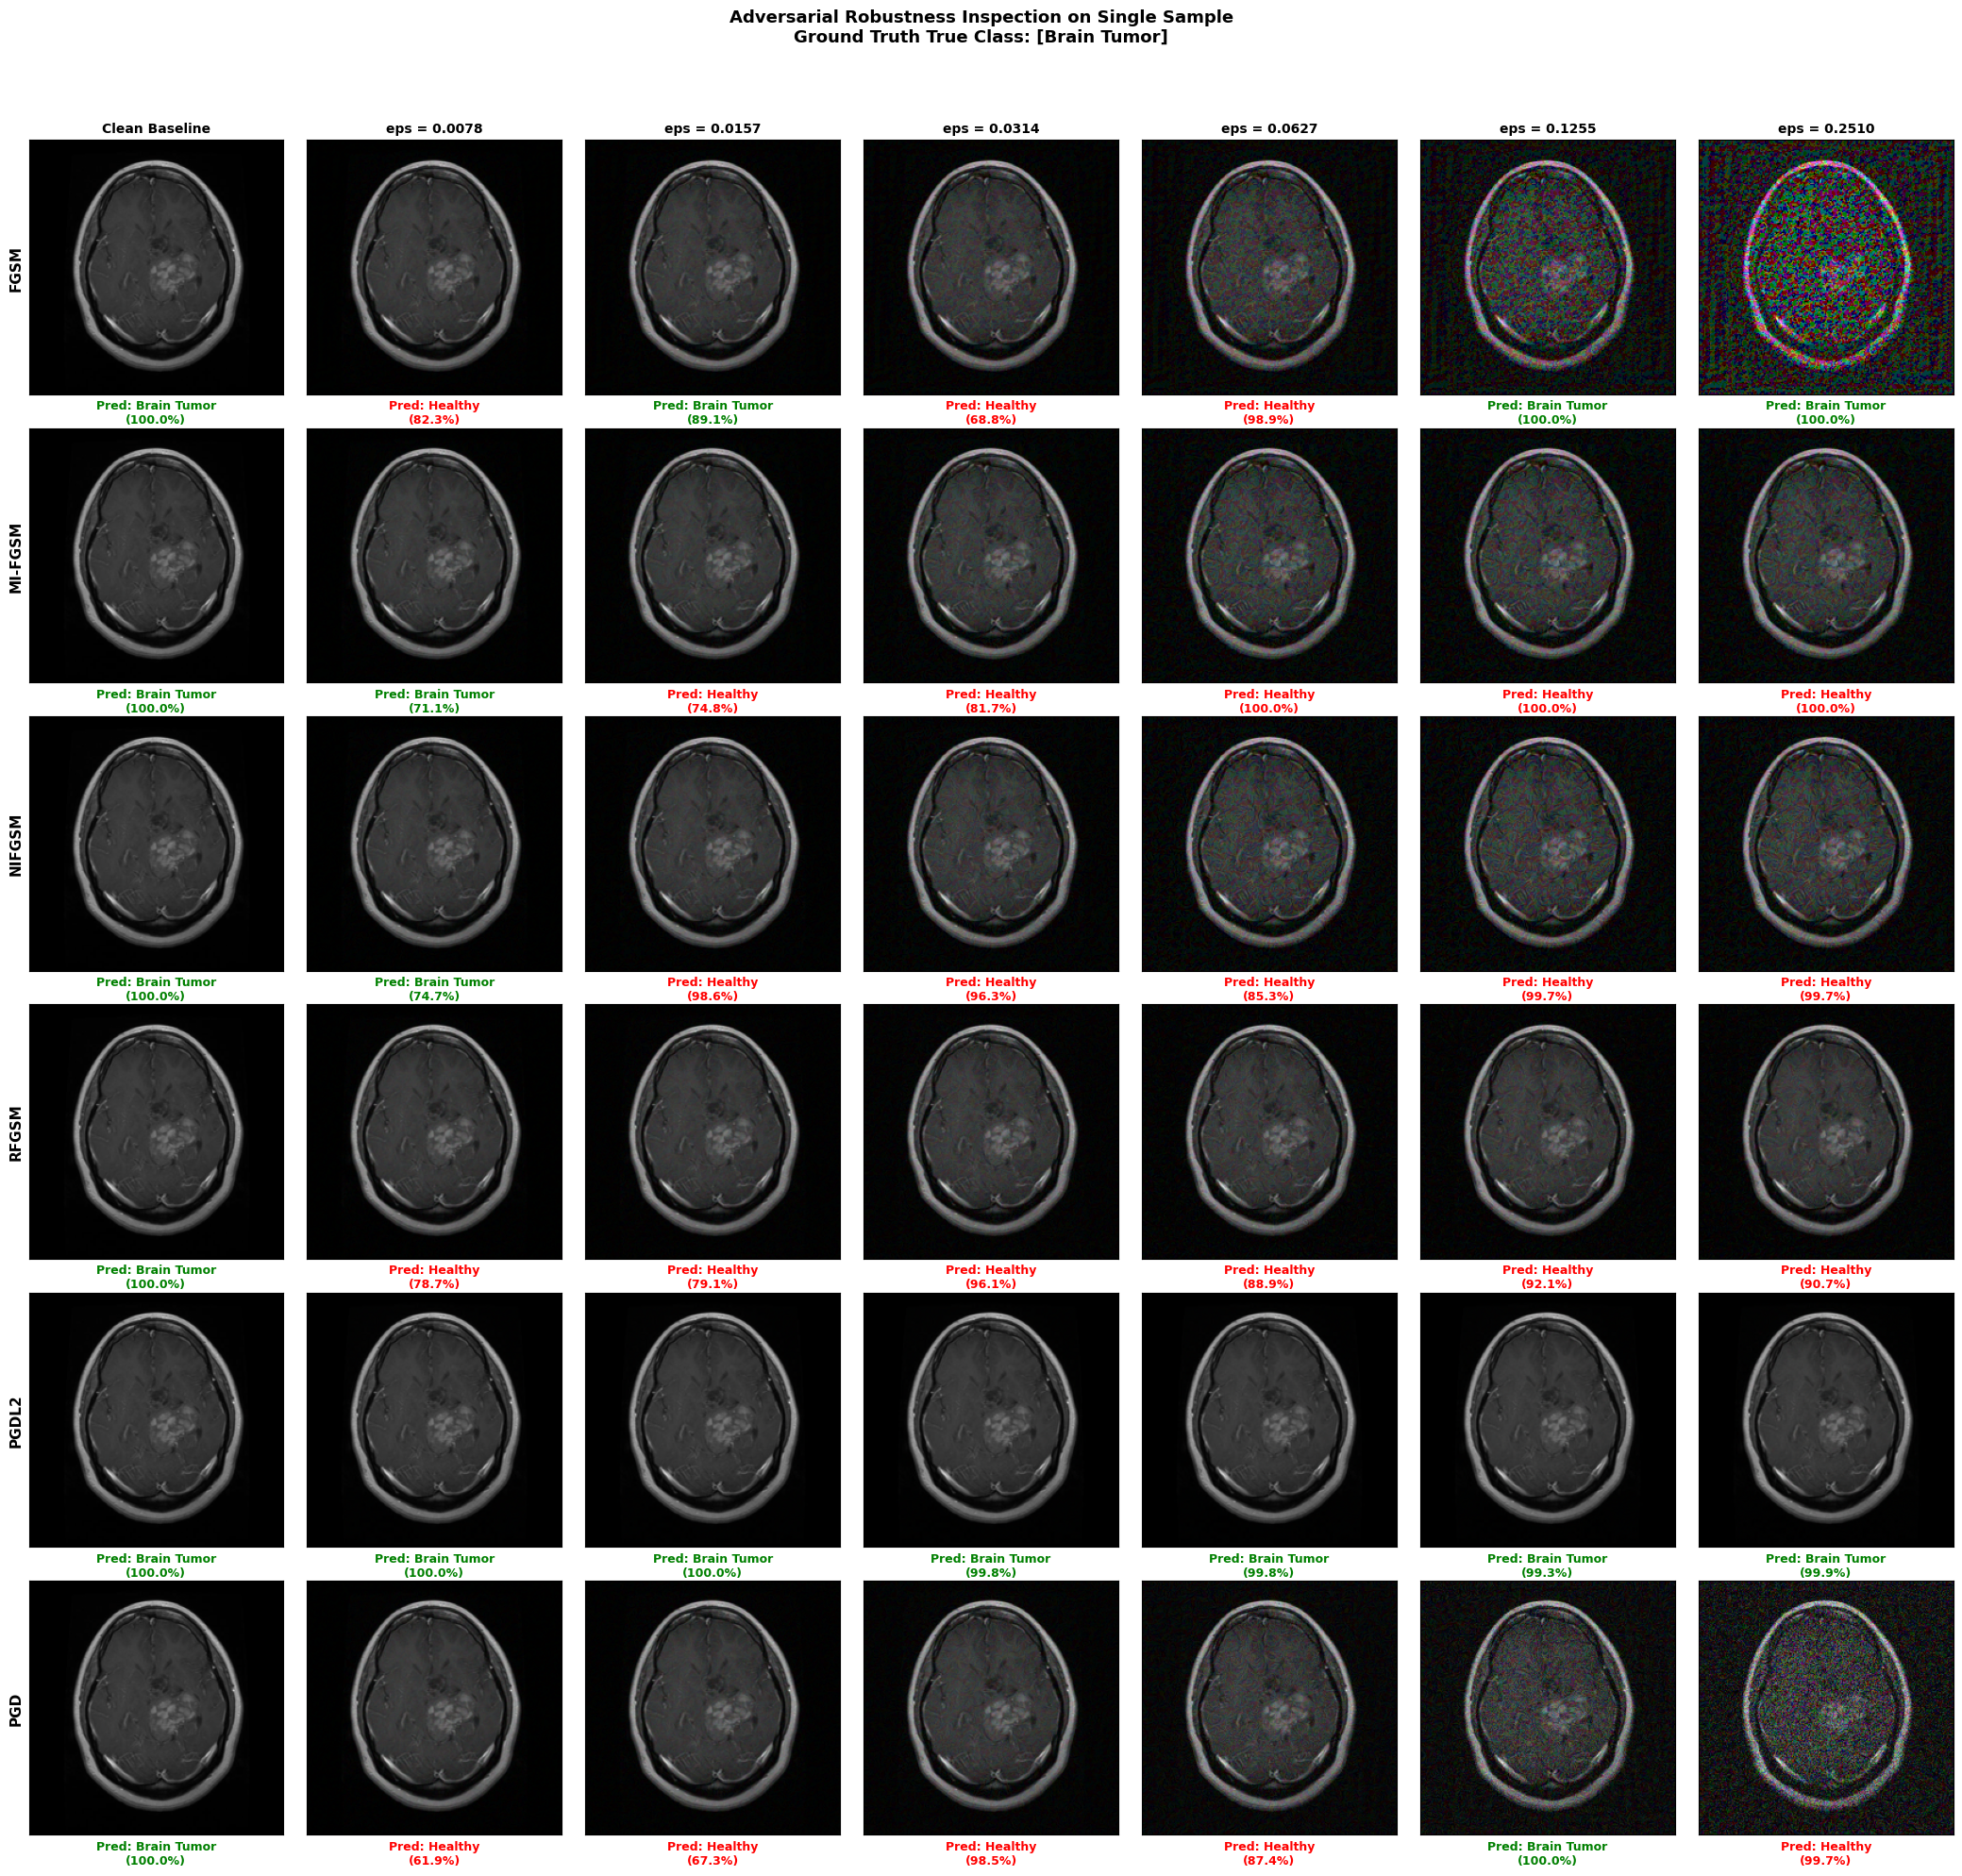

In [185]:
visualize_cached_grid_with_preds(sample_cache, classes, eps_list=epsilon_values)

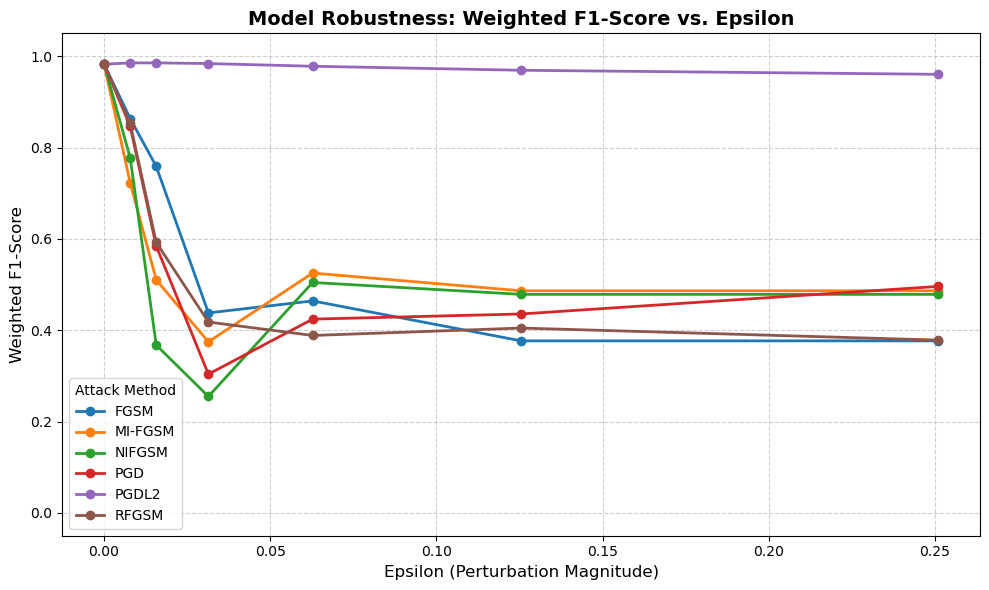

In [190]:
plot_f1_vs_epsilon(results_df)